In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_excel(r"C:\Users\Lenovo\OneDrive\Desktop\intershala\Machine_learning\course_Assignments\final_Project\heart_disease_data.xlsx")



In [2]:
print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())

         date    country    id  active  age  alco  ap_hi  ap_lo  cholesterol  \
0  2026-01-01  Australia  1000       0   60     0    131     74            1   
1  2026-01-02  Australia  1001       0   22     0    129     92            3   
2  2026-01-03         UK  1002       1   48     0    154     81            2   
3  2026-01-04     Canada  1003       0   44     1    177     76            1   
4  2026-01-05      India  1004       1   73     0    105    102            1   

   gender  gluc  height occupation  smoke  weight  disease  
0    Male     3     151      Clerk      1    82.2        1  
1  Female     1     180    Student      0    55.9        0  
2    Male     1     158    Teacher      0    97.6        0  
3    Male     3     174   Business      1    74.5        1  
4  Female     2     150   Business      0    92.0        0  
          date    country    id  active  age  alco  ap_hi  ap_lo  cholesterol  \
45  2026-02-15        USA  1045       1   34     1    103     84        

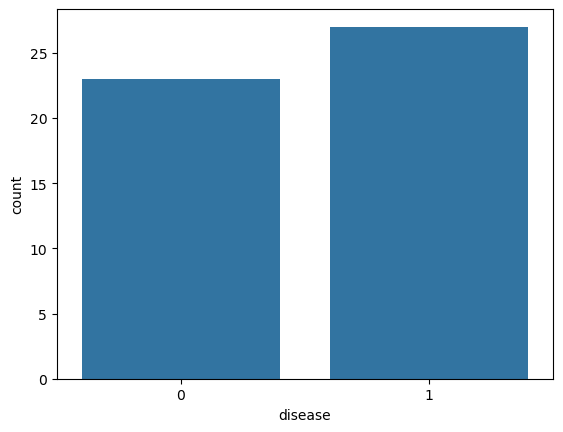

In [3]:
#EDA
sns.countplot(x="disease",data=df)
plt.show()

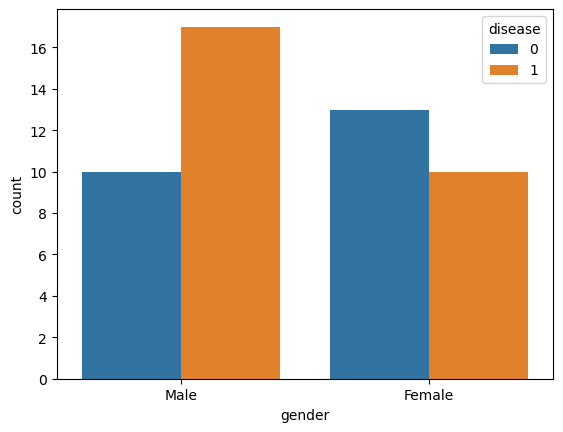

In [7]:
#Gender vs Disease
sns.countplot(x="gender",hue="disease",data=df)
plt.show()

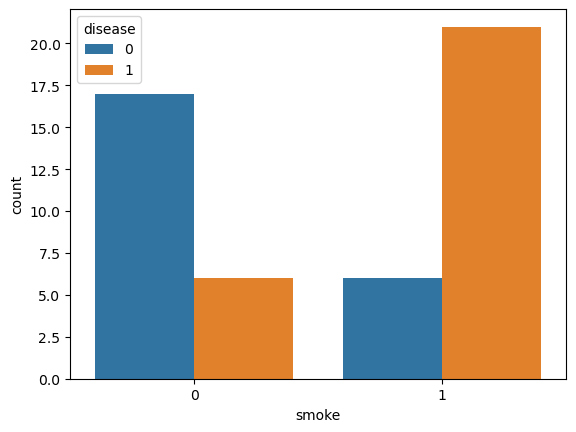

In [8]:
sns.countplot(x="smoke",hue="disease",data=df)
plt.show()

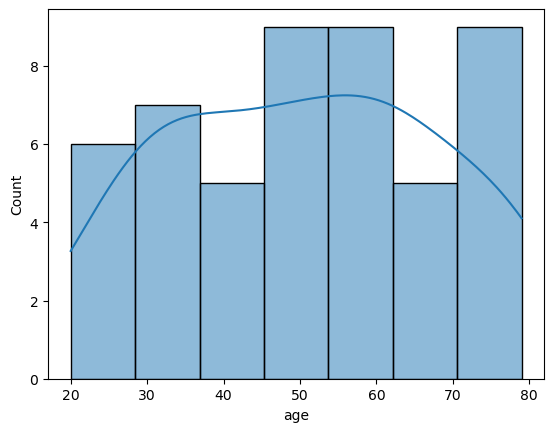

In [9]:
sns.histplot(df["age"],kde=True)
plt.show()

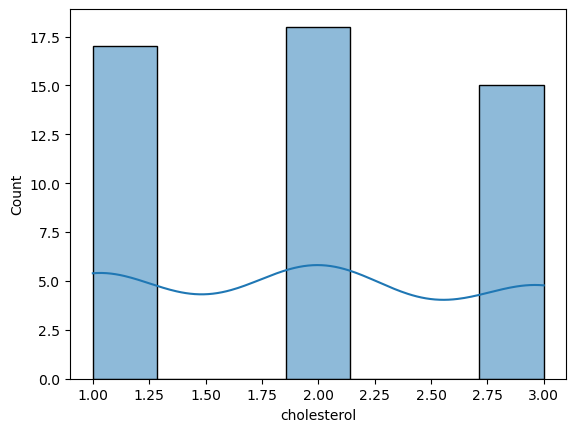

In [10]:
sns.histplot(df["cholesterol"],kde=True)
plt.show()

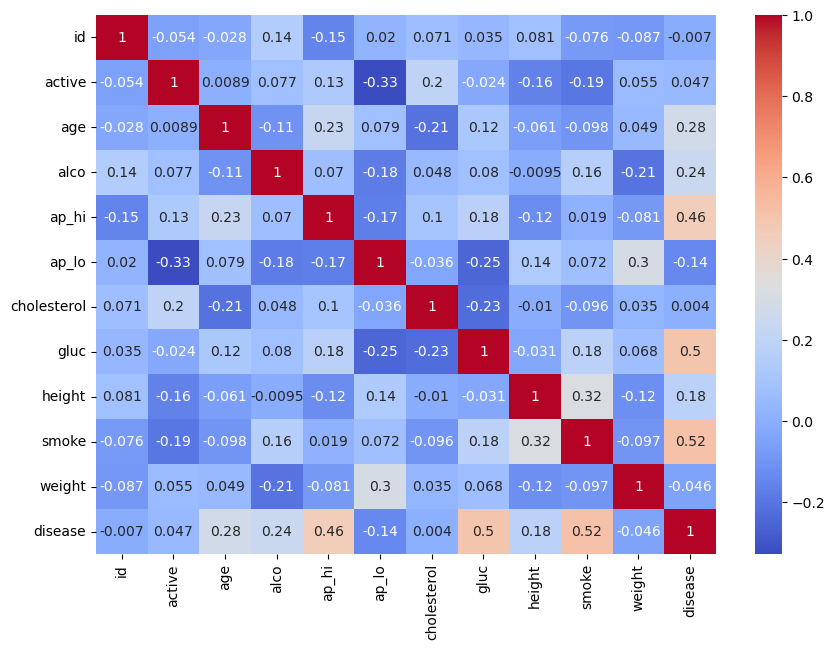

In [11]:
numeric=df.select_dtypes(include=['int64','float64'])
plt.figure(figsize=(10,7))
sns.heatmap(numeric.corr(),annot=True,cmap="coolwarm")
plt.show()

In [3]:
#removing unecessary column
df.drop(["id","date"],axis=1,inplace=True)
#Missing values

print(df.isnull().sum())
df.fillna(method="ffill",inplace=True)


country        0
active         0
age            0
alco           0
ap_hi          0
ap_lo          0
cholesterol    0
gender         0
gluc           0
height         0
occupation     0
smoke          0
weight         0
disease        0
dtype: int64


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_27756\1966756426.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method="ffill",inplace=True)


In [4]:
#Encode Categorical data

from sklearn.preprocessing import LabelEncoder

le=LabelEncoder()

for col in df.columns:
    if df[col].dtype=="object":
        df[col]=le.fit_transform(df[col])

print(df.head())

   country  active  age  alco  ap_hi  ap_lo  cholesterol  gender  gluc  \
0        0       0   60     0    131     74            1       1     3   
1        0       0   22     0    129     92            3       0     1   
2        3       1   48     0    154     81            2       1     1   
3        1       0   44     1    177     76            1       1     3   
4        2       1   73     0    105    102            1       0     2   

   height  occupation  smoke  weight  disease  
0     151           1      1    82.2        1  
1     180           6      0    55.9        0  
2     158           7      0    97.6        0  
3     174           0      1    74.5        1  
4     150           0      0    92.0        0  


In [5]:
X=df.drop("disease",axis=1)
y=df["disease"]

In [6]:
#Train Test Split

from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
X,y,test_size=0.20,random_state=42
)

In [8]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression(max_iter=1000)
lr.fit(X_train,y_train)
lr_pred=lr.predict(X_test)

In [9]:
#DecisionTree
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier(random_state=42)
dt.fit(X_train,y_train)
dt_pred=dt.predict(X_test)

In [12]:
#support vector Machine
from sklearn.svm import SVC
svm=SVC()
svm.fit(X_train,y_train)
svm_pred=svm.predict(X_test)

In [13]:
from sklearn.metrics import accuracy_score
print("Logistic Regression:",accuracy_score(y_test,lr_pred))
print("Decision Tree:",accuracy_score(y_test,dt_pred))
print("SVM",accuracy_score(y_test,svm_pred))

Logistic Regression: 0.9
Decision Tree: 0.8
SVM 0.6


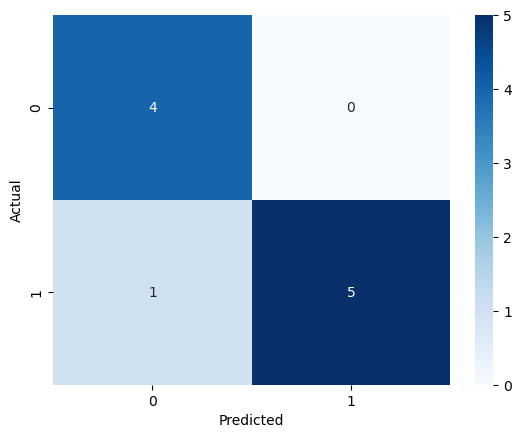

In [14]:
#confusion Matrix
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,lr_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [15]:
#classification report
from sklearn.metrics import classification_report
print(classification_report(y_test,lr_pred))

              precision    recall  f1-score   support

           0       0.80      1.00      0.89         4
           1       1.00      0.83      0.91         6

    accuracy                           0.90        10
   macro avg       0.90      0.92      0.90        10
weighted avg       0.92      0.90      0.90        10



In [16]:
models=["Logistic Regression","Decision Tree","SVM"]

accuracy=[
accuracy_score(y_test,lr_pred),
accuracy_score(y_test,dt_pred),
accuracy_score(y_test,svm_pred)
]

comparison=pd.DataFrame({
"Model":models,
"Accuracy":accuracy
})

print(comparison)

                 Model  Accuracy
0  Logistic Regression       0.9
1        Decision Tree       0.8
2                  SVM       0.6


In [ ]:
new_patient=X.iloc[[0]]